# 200 ms all-channel forecast ensemble

Does forecasting every sensor channel provide more useful uncertainty than forecasting only hip angles?

Read top-to-bottom: setup → equations → architecture → training → figures → LOTO → interpretation.
**Safe default:** saved-result exploration only; training is disabled.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'ml/sci_rob/vanilla/registry.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter within this repository.')
sys.path.insert(0, str(ROOT / 'notebooks/sci_rob/model_exploration'))
get_ipython().run_line_magic('matplotlib', 'inline')
from _exploration import *
import torch
from dataclasses import asdict
torch.set_num_threads(2)  # small architecture checks; training CLI runs separately
torch.manual_seed(0)
RUN_TRAINING = False
print('Repository:', ROOT)
print('Kernel:', sys.executable)

Repository: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton
Kernel: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python


In [2]:
KEY = 'forecast-all'
RUN = ROOT / RUNS[KEY]
inventory(RUN)

**Artifact directory:** `ml/sci_rob/vanilla/runs/forecast_all`

,artifact,available
0,report.json,False
1,final.pt,False
2,eval_test.json,False
3,figures,False


No completed training report here. Architecture/commands below are not results.


## Data and evaluation contract

- Input: **16 channels × 200 samples**, one second at 200 Hz; stored window stride 10 samples.
- Original ID tasks: level ground (LG), ramp ascent (RA), ramp descent (RD).
  Original pseudo-OOD tasks: stair ascent (SA), stair descent (SD), standing (ST), transitions (TR).
- Participants: 12 train / 4 validation / 4 test. Task availability differs by participant.
  Input scaling is fitted on training data, never refitted on test data.
- Scoring does **not** predict a task label. High $\Psi$ means more anomalous.

$$\widetilde\Psi_t=\operatorname{median}(\Psi_{t-9},\ldots,\Psi_t),\qquad
\tau=Q_{0.995}(\widetilde\Psi_{\mathrm{train,ID}}),\qquad
\widehat o_t=\mathbf1[\widetilde\Psi_t>\tau].$$

Filtering restarts for each trial; early windows use the available history. The ten-score
filter corresponds to the repository's nominal 0.5 s smoothing setting, **not** ten raw samples.

$$\mathrm{recall}=\frac{TP}{TP+FN},\quad
\mathrm{specificity}=\frac{TN}{TN+FP},\quad J=\mathrm{recall}+\mathrm{specificity}-1.$$

AUROC measures ranking across thresholds; it is **not the fraction of OOD detected**.
OOD is the positive class. Tables below show J on −1 to 1, although source JSON stores 100J.
Scores and thresholds are not calibrated probabilities of being unsafe.

## Model and mathematics

The target extends bilateral angle forecasting to all 16 standardized channels:
 $$y_t=x_{\mathrm{channels}}(t+40),\qquad D=16.$$
 Seven identical TCN trunks have 16 linear outputs each. Future rows are matched within trials;
 unavailable future targets are masked. Per-channel disagreement can be inspected before averaging:
 $$\Psi_d(x)=\frac17\sum_m(f_{md}(x)-\bar f_d(x))^2,\qquad
 \Psi(x)=\frac1{16}\sum_{d=1}^{16}\Psi_d(x).$$
 Standardization changes units but does not make all channels equally predictable or equally
 relevant to control. A large channel score is not, by itself, proof that its sensor is faulty.

For branch $m$ and target dimension $d$, train with masked mean squared error:

$$\mathcal L=\frac{\sum_{n,m,d}a_{nd}(f_{md}(x_n)-y_{nd})^2}
{M\sum_{n,d}a_{nd}},\qquad M=7.$$

$a$ is the target-validity mask. The online score uses no target labels:

$$\bar f_d(x)=\frac1M\sum_m f_{md}(x),\qquad
\Psi(x)=\frac1D\sum_d\frac1M\sum_m(f_{md}(x)-\bar f_d(x))^2.$$

This is population variance across branches, not sample variance. Agreement is a candidate
uncertainty signal, **not a guarantee that an input is familiar or a prediction is correct**.

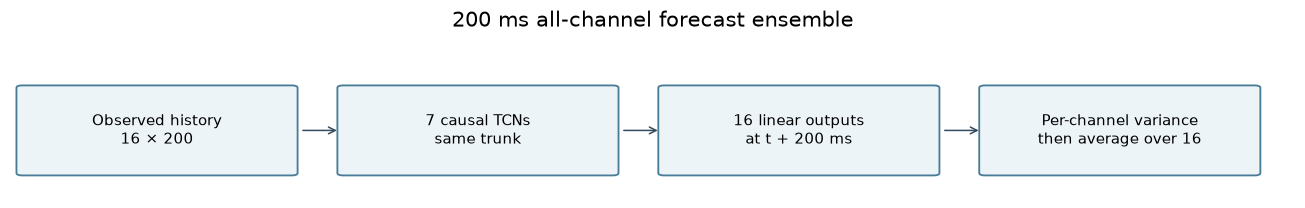

In [3]:
diagram([['Observed history\n16 × 200', '7 causal TCNs\nsame trunk', '16 linear outputs\nat t + 200 ms', 'Per-channel variance\nthen average over 16']], '200 ms all-channel forecast ensemble')

### Executable architecture check

This constructs **fresh random weights** and checks shapes only. The saved figures later come from trained runs; this dummy forward pass does not.

In [4]:
from models.ensemble import create_ensemble
model = create_ensemble(16, 16, activation='linear')
example = torch.zeros(2, 16, 200)
output = model_shapes(model, example)

GaitPhaseEnsemble: 324,562 parameters
Input: (2, 16, 200)   Outputs: [(2, 7, 16)]
Layer table shows one representative branch; weights are not shared.


,module,class,direct parameters
0,network.0.conv,CausalConv1d,9630
1,network.0.norm,BatchNorm1d,60
2,network.0.relu,ReLU,0
3,network.1.conv,CausalConv1d,18030
4,network.1.norm,BatchNorm1d,60
5,network.1.relu,ReLU,0
6,network.2.conv,CausalConv1d,18030
7,network.2.norm,BatchNorm1d,60
8,network.2.relu,ReLU,0
9,fc,Linear,496


## Training


Twelve leave-one-subject-out (LOSO) folds over the training participants select the final
epoch count from held-out-subject loss. A freshly initialized ensemble then trains on all
training participants for that duration. Defaults: Adam, learning rate 0.001, batch 1024,
maximum 60 fold epochs, patience 10. The report below is authoritative for a saved run.
Branches have independent weights/initialization but see the same training batches.
 This is implemented in the production registry but no completed forecast_all report/evaluation was found when this notebook was created. Do not substitute forecast_angle or smoke-run results.

In [5]:
from registry import get
config_class = get(KEY).config()
display(pd.Series(asdict(config_class()), name='current default').to_frame())

,current default
lr,0.001
batch_size,1024
max_epochs,60
patience,10
seed,0
device,None
threshold_percentile,99.5
n_members,7
out_dir,ml/sci_rob/vanilla/runs/forecast_all
loso_folds,None


### Saved training configuration and learning curves

Current defaults can differ from a past run. Below we read the report; missing reports remain explicitly missing. Loss scales from different objectives are not directly comparable.

In [6]:
config_and_history(RUN)

No saved training history.


### Optional: run the real training pipeline

This can take hours. The commands use this kernel’s Python and write to a **new** directory. Set `RUN_TRAINING=True` in the setup cell only when ready. Existing runs are protected. After completion, set `RUN = NEW_RUN` and rerun the result cells.

In [7]:
NEW_RUN = ROOT / 'notebooks/sci_rob/model_exploration/runs' / KEY
commands = training_commands(KEY, NEW_RUN)
run_commands(commands, NEW_RUN, enabled=RUN_TRAINING)

/Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/ml/sci_rob/vanilla/main.py all --model forecast-all --out /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/notebooks/sci_rob/model_exploration/runs/forecast-all

Preview only. Set RUN_TRAINING=True explicitly to run.


## Saved test results

These values come directly from `eval_test.json`. An optimized test-ROC threshold, where reported, is diagnostic—not a validated operating point.

In [8]:
results_table(RUN)

No saved test evaluation; no performance is inferred.


## Model behavior through figures

Images are embedded from the existing run, without rewriting it. Captions explain what each figure can and cannot establish.

In [9]:
gallery(RUN, [('psi_by_task.png', 'Score distributions by task. The threshold is an operating point, not an ID/OOD boundary guaranteed by the model.'), ('roc.png', 'Threshold sweep: ranking quality, not the fraction detected at the saved threshold.'), ('detection_by_task.png', 'Actual flag rates at the saved training threshold; flags on ID tasks are false alarms.'), ('loso.png', 'Training duration selection across held-out training participants; this is LOSO, not task holdout.')])

**psi_by_task.png** — Score distributions by task. The threshold is an operating point, not an ID/OOD boundary guaranteed by the model.

Not available: ml/sci_rob/vanilla/runs/forecast_all/figures/psi_by_task.png


**roc.png** — Threshold sweep: ranking quality, not the fraction detected at the saved threshold.

Not available: ml/sci_rob/vanilla/runs/forecast_all/figures/roc.png


**detection_by_task.png** — Actual flag rates at the saved training threshold; flags on ID tasks are false alarms.

Not available: ml/sci_rob/vanilla/runs/forecast_all/figures/detection_by_task.png


**loso.png** — Training duration selection across held-out training participants; this is LOSO, not task holdout.

Not available: ml/sci_rob/vanilla/runs/forecast_all/figures/loso.png


## Leave-one-task-out (LOTO) stress test

SA: stair ascent; ST: standing; TR: transitions. Each run excludes the named task from **all training participants**, trains on the other six, and tests on held-out participants. This differs from LOSO epoch selection.

Standing test data come from one trial of one participant: 621 overlapping windows, or 600 for the gait-phase subset. Gait-phase LOTO uses fewer labelled windows overall. Raw window counts are not independent repetitions; cross-run changes do not isolate a causal training effect.

In [10]:
loto_results(KEY)

No LOTO run mapping exists for this variant.


## LOTO score spread and threshold what-if

Each figure uses one separately trained holdout run: **only the named held-out task is
orange (OOD)**; the other six are blue (ID). The black dashed line is that run's saved
training threshold. Black bars span the middle 50% (IQR), with a tick at the median.
Density shapes use at most 1,500 quantile-spaced points per task; all medians, IQRs and
flag rates use **every saved test window**. Non-GAN scores use log10 axes when positive.
The plotted scores already include the original per-trial smoothing; they are not filtered again.

$$\operatorname{recall}(\tau)=\frac{\sum_{i:y_i=1}\mathbf{1}[\widetilde\Psi_i>\tau]}{N_{\rm OOD}},
\qquad \operatorname{FPR}(\tau)=\frac{\sum_{i:y_i=0}\mathbf{1}[\widetilde\Psi_i>\tau]}{N_{\rm ID}}.$$

**Try a threshold:** replace a `None` in `LOTO_THRESHOLDS` with a numeric score threshold
(in original units, **not log10**), then rerun this cell. A purple line and exact per-task
flag rates show the what-if; `None` uses the saved threshold. The right-hand staircase
and table show recall **and ID false alarms**, not AUROC. Changing the threshold does
not change AUROC, retrain anything, or overwrite saved results.

These are **exploratory test-set what-ifs**, not validated new operating points. Choose a
final threshold using validation data, not whichever test threshold looks best. Rates
are window-weighted; overlapping windows (especially the single standing trial) are
not independent repetitions. Missing runs remain explicitly unavailable.

In [11]:
from _loto_exploration import loto_score_explorer, threshold_rates
LOTO_THRESHOLDS = {'SA': None, 'ST': None, 'TR': None}
LOTO_SCORE = 'primary'
loto_bundles = loto_score_explorer(KEY, score=LOTO_SCORE, thresholds=LOTO_THRESHOLDS)
# Exact custom query, e.g.: threshold_rates(loto_bundles['ST'], [0.59, 0.60])

### Held out: SA — stair ascent

Unavailable — No registered LOTO run directory for forecast-all. No plot or performance is inferred.


### Held out: ST — standing

Unavailable — No registered LOTO run directory for forecast-all. No plot or performance is inferred.


### Held out: TR — transitions

Unavailable — No registered LOTO run directory for forecast-all. No plot or performance is inferred.


## Takeaway and next checks

Treat this as an executable ablation setup until a complete run exists. Compare against angle forecasting with the same horizon and protocol; inspect whether harder IMU channels dominate the aggregate score.

Keep score/threshold selection on validation data. Report both ranking and recall at a declared false-alarm budget, repeat seeds, and quantify participant/trial-level variation before making robustness claims.

In [12]:
source_links(['ml/sci_rob/vanilla/registry.py', 'ml/sci_rob/vanilla/targets.py', 'ml/sci_rob/vanilla/training/synthetic.py'])

Implementation sources: [registry.py](../../../ml/sci_rob/vanilla/registry.py), [targets.py](../../../ml/sci_rob/vanilla/targets.py), [synthetic.py](../../../ml/sci_rob/vanilla/training/synthetic.py)